# Figure 4

Preparatory representations of target and competitor locations in early visual cortex predict search behavior. Reads in `dataframes/evc_prep_curve_last.csv` computed by `precompute/fig4_glm_resids_aggregate.py`


In [1]:
import os.path as op

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mgvs_release.plotting import setup_style, save_fig

setup_style()

save_dir = "../plots/"

## Read in aggregated EVC and last saccade data

In [2]:
search_data_all = pd.read_csv(op.join('../dataframes', 'evc_prep_curve_last.csv'))

## Fig 4B: Predictive target location representations in EVC


In [3]:
search_data_all_180 = search_data_all.query("ang_dist_bin==180.0").copy()
search_data_all_180['ang_dist_bin'] = -180
search_data_all_plot = pd.concat([search_data_all, search_data_all_180])
search_data_acc_mean = search_data_all_plot.query(
    "cue_validity=='valid'"
).groupby(['subj', 'ang_dist_bin', 'next_warp_resp']).mean(numeric_only=True).reset_index()

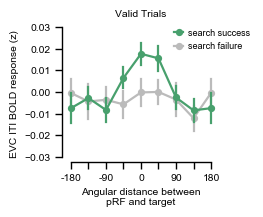

In [4]:
pal = ['#bbbbbb', sns.desaturate('#40a86c', .85)]
f, ax = plt.subplots(1, 1, figsize=(2.53, 2.2))
ax = sns.pointplot(x='ang_dist_bin', y='bold_z_all', estimator=np.mean, errorbar='se',
                   hue='next_warp_resp',
                   palette=pal,  linewidth=1.6,
                    order = [-180.0, -135.0, -90.0, -45.0, 0.0, 45.0, 90.0, 135.0, 180.0],
                   data=search_data_acc_mean)
ax.set(ylabel='EVC ITI BOLD response (z)', title='Valid Trials',
       xlabel='Angular distance between\npRF and target')
ax.set(yticks=np.arange(-.03, .031, .01), ylim=[-.032, .031], xticks=range(9),
       xticklabels=["-180", "", "-90", "", "0", "", "90", "", "180"])
sns.despine(trim=True)

ax.legend_=None
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], ['search success', 'search failure'],
          bbox_to_anchor=[.66, .75], frameon=False, handletextpad=.5,
         handlelength=1, title='')

f.tight_layout()
save_fig(f, op.join(save_dir, 'fig4b'))

## Fig 4C: Predictive competitor location representations in EVC


In [5]:
comp_data_all_180 = search_data_all.query("comp_dist_bin==180.0").copy()
comp_data_all_180['comp_dist_bin'] = -180
comp_data_all_plot = pd.concat([search_data_all, comp_data_all_180])
comp_data_acc_mean = comp_data_all_plot.query(
    "cue_validity=='valid' & next_warp_resp==False"
).groupby(['subj', 'comp_dist_bin', 'next_comp_resp']).mean(numeric_only=True).reset_index()

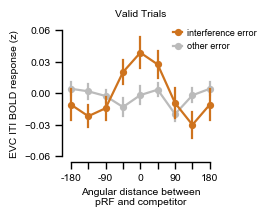

In [6]:
pal = ['#bbbbbb', sns.desaturate('#de730e', .85)]
f, ax = plt.subplots(1, 1, figsize=(2.58, 2.2))
ax = sns.pointplot(x='comp_dist_bin', y='bold_z_all', estimator=np.mean, errorbar='se', hue='next_comp_resp',
                    palette=pal, linewidth=1.6,
                    order = [-180.0, -135.0, -90.0, -45.0, 0.0, 45.0, 90.0, 135.0, 180.0],
                   data=comp_data_acc_mean)
ax.set(ylabel='EVC ITI BOLD response (z)', title='Valid Trials',
       xlabel='Angular distance between\npRF and competitor')
ax.set(yticks=np.arange(-.06, .065, .03), ylim=[-.065, .065], xticks=range(9),
       xticklabels=["-180", "", "-90", "", "0", "", "90", "", "180"])
sns.despine(trim=True)

ax.legend_=None
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], ['interference error', 'other error'],
          bbox_to_anchor=[.66, .75], frameon=False, handletextpad=.5,
         handlelength=1, title='')

f.tight_layout()
save_fig(f, op.join(save_dir, 'fig4c'))

## Fig 4D: Mean EVC response per pRF location, separated by behavioral outcome

In [7]:
search_data_all['resp_type'] = 'other'
search_data_all.loc[search_data_all['next_warp_resp']==True, 'resp_type'] = 'warp'
search_data_all.loc[search_data_all['next_comp_resp']==True, 'resp_type'] = 'competitor'

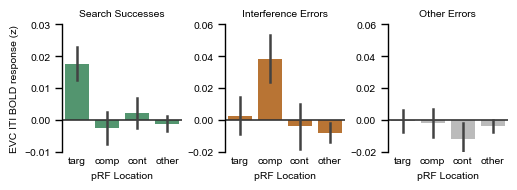

In [8]:
f, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(5.2, 2))
search_data_mean = search_data_all.groupby(
    ['subj', 'cue_validity', 'cond', 'resp_type']).mean(numeric_only=True).reset_index()
sns.barplot(x='cond', y='bold_z_all', errorbar='se',
                order = ['target', 'competitor', 'control', 'other'],
                color = sns.desaturate('#40a86c', .85),
                data=search_data_mean.query("cue_validity=='valid' & resp_type=='warp'"),
           ax=ax1)

ax1.set(ylabel='EVC ITI BOLD response (z)', xlabel='pRF Location', title='Search Successes',
        ylim=[-.01, .03], xticks=range(4), xticklabels=['targ', 'comp', 'cont', 'other'])

sns.barplot(x='cond', y='bold_z_all', errorbar='se',
                order = ['target', 'competitor', 'control', 'other'],
                color = sns.desaturate('#de730e', .85),
                data=search_data_mean.query("cue_validity=='valid' & resp_type=='competitor'"),
           ax=ax2)
ax2.set(ylabel='', xlabel='pRF Location', title='Interference Errors',
       ylim=[-.02, .06], xticks=range(4), xticklabels=['targ', 'comp', 'cont', 'other'])

sns.barplot(x='cond', y='bold_z_all', errorbar='se',
                order = ['target', 'competitor', 'control', 'other'],
                color = '#bbbbbb',
                data=search_data_mean.query("cue_validity=='valid' & resp_type=='other'"),
           ax=ax3)
ax3.set(ylabel='', xlabel='pRF Location', title='Other Errors',
        ylim=[-.02, .06], xticks=range(4), xticklabels=['targ', 'comp', 'cont', 'other'])

ax1.axhline(y=0, c=".2", ls="-", zorder=1)
ax2.axhline(y=0, c=".2", ls="-", zorder=1)
ax3.axhline(y=0, c=".2", ls="-", zorder=1)


f.tight_layout(w_pad=.5)
sns.despine(bottom=True)
ax1.tick_params(axis='x', which='both', size=0)
ax2.tick_params(axis='x', which='both', size=0)
ax3.tick_params(axis='x', which='both', size=0)

save_fig(f, op.join(save_dir, 'fig4d'))

### Robustness check: excluding fixation-break trials


In [9]:
fix_breaks = pd.read_csv('../dataframes/fix_break_trials.csv')
fix_breaks['subj'] = fix_breaks['subject']

In [10]:
no_fixbreak_df = search_data_all.merge(fix_breaks, on=['subj', 'run', 'trial'],
                                    how='left', indicator=True)
no_fixbreak_df = no_fixbreak_df[no_fixbreak_df['_merge'] == 'left_only'].drop(columns=['_merge'])

In [11]:
no_fixbreak_df.to_csv('../dataframes/evc_prep_curve_last_nofixbreaks.csv')